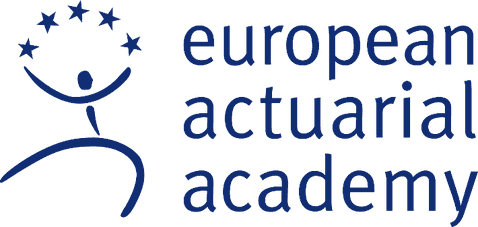

<h1 style="color:#0F2B72;">Fit4AI compact</h1>
<h2 style="color:#0F2B72;">Module 3 – Artificial Intelligence – Hands-On Experience and Practical Application</h2>
<h3 style="color:#0F2B72;">Data Science and AI in Insurance Practice</h3>
<div style="border:0px; background-color:#0F2B72; width:100%; height:1px;">&nbsp;</div>
<h4 style="color:#0F2B72;" class="unlisted unnumbered">EAA Inhouse Seminar SAV | Zurich, 19/20 November 2026</h4>
<p style="color:#0F2B72;">Dr Johannes Schupp<br>Jupyter Notebook (Python)</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/fit4ai-compact-20261119/blob/main/Fit4AI_3_Data_Science_and_AI_in_Insurance_Practice.ipynb)

Repository: [simonhatzesberger/fit4ai-compact-20261119](https://github.com/simonhatzesberger/fit4ai-compact-20261119) – code under the [MIT License](https://github.com/simonhatzesberger/fit4ai-compact-20261119/blob/main/LICENSE).

#### Setup

Run the following code cell first (**Shift + Enter**). It works locally and in Google Colab:

* packages that are missing are installed with `pip` (Google Colab already has all of them);
* the data files `titanic.csv` and `Medicare.txt` are read from the folder `data/` next to this notebook; if they are not there (e.g. in Colab), they are downloaded from the course repository;
* the screenshots and figures in the text cells are loaded from the course repository on GitHub, so they need an internet connection (the HTML version of this notebook in the course materials contains them embedded).

In [1]:
# Setup: required packages and data files (runs locally and in Google Colab)
import importlib.util
import os
import subprocess
import sys
import urllib.request

# Install only missing packages (no version pins: preinstalled versions stay unchanged)
packages = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "sklearn": "scikit-learn", "xgboost": "xgboost",
            "statsmodels": "statsmodels", "plotly": "plotly"}
missing = [pip_name for module, pip_name in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

# Data files: from data/ next to the notebook, otherwise downloaded from the course repository
REPO_RAW = "https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main"
os.makedirs("data", exist_ok=True)
for name in ["titanic.csv", "Medicare.txt"]:
    path = os.path.join("data", name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"{REPO_RAW}/data/{name}", path)
        print("Downloaded", path)
print("Setup complete.")

Setup complete.


**Objective**:

Participants are able to independently conduct, evaluate, and appropriately present basic data analyses using data science and AI methods. They follow the best practices of the actuarial data science (ADS) community.

**Learning objectives**:

Based on a simple question and a given dataset, independently conduct a data science or AI analysis. The phases of a data mining process are followed, and the result is documented and prepared in an appropriate form, e.g., in a notebook or using a cloud framework. This includes preparing the development environment, processing the data to be used, applying simple machine learning models, and finally discussing the results.

## Content

* **1. The Development Environment**
    * Jupyter Notebooks
    * Cloud Development
    * Local Development
    * Virtual Environments

* **2. Hands-On Practice**
    * Titanic / Medicare
    * Coding Assistance

* **3. Best Practices and Outlook**

* **Appendix: Conceptual Knowledge**

    * Description of the scope of Python basics
    * Basics of plotting and visualisation

---

## 1. Development Environment

* The material in this module provides an initial overview of tools and programs for the practical implementation of **data science and AI methods**.
* `Best practices`, `standards`, and `conventions` are introduced.
* The basis for these materials is the programming language `Python` with the file format `Jupyter Notebook` (.ipynb).
* For efficient use, it is necessary to become familiar with __virtual Python environments__.
* Relevant extensions such as `scikit-learn`, `matplotlib`, and the use of `virtual environments` are also discussed.

### 1.1. Jupyter Notebooks

* A central element in many AI development workflows is the `Notebook`.
* The notebook (**.ipynb**) is a file type based on `JSON` that has two advantages over classic program files:
    * `Code cells` can be mixed with `Markdown` content.
    * Through interactive execution (e.g., using `ipykernel`), development becomes much more flexible.


#### Concept

* By alternating between `code` and `Markdown` fragments, the format allows **documentation** to be integrated into the analysis.
* When appropriately structured, this results in a very *accessible* presentation of the analytics process.
* For production applications, a Docker container with the virtual environment, etc., is typically used, not the notebook itself.
    * Therefore, it makes sense to design code to be reusable and abstracted in _classes_ and _functions_.
    * In-depth considerations of _DevOps development_ are __*not*__ part of this seminar.


#### Markdown

* Markdown cells can be formatted:

    * The characters `*` and `_` indicate formatting:
        * Single use, `*italic*`, results in *italic* text.
        * Double use, `**bold**`, results in **bold** text.
        * Triple use, `***bold italic***`, results in ***bold italic*** text.
    * The `#` character is used to mark heading levels:
        * One `#` is the main heading, two `##` is the next smaller heading, etc.
        * Headings structure the notebook into an outline, which is displayed in e.g. VSCode in the sidebar and makes the document easier to navigate.

    * Horizontal separators are often desirable. This is achieved with the combination `---`:
    ---

**Continued: Markdown**

* Lists are created with (indented) asterisks `*`:
    * `* First level, first item`
    * `* First level, second item`
        * `* Second level under the second item` (indented by four spaces)
        * `* Second level, second item` (indented by four spaces)

* Internal and external hyperlinks can be set:
    * A link with title: `[EAA](https://www.actuarial-academy.com "European Actuarial Academy")`: [EAA](https://www.actuarial-academy.com "European Actuarial Academy")
    * Internal link: The process requires two parts:
        * The part of the document to be referenced must be marked with `<a id="reference_target"></a>`. (HTML anchor)
        * The linking part is then: `[To linked part](#reference_target)`


#### Sharing and Exporting

* `.ipynb` files can be shared like text files and read with common editors.
    * To execute the code, the required data and an identical Python environment are necessary.
* Notebooks can be exported in many formats.
    * Common exports are to `HTML` and `PDF`.
* Using `cell tags`, so-called `slide types` can be specified:
    * Notebooks can be exported as __reveal.js presentations__ that are played in the browser.
    * The cells are then _shown_, _revealed_, or _ignored_ for the presentation as specified.

---

### 1.2. Cloud Development

* Many data science/AI applications can be run on `virtual servers` without having to install anything on the local computer – all you need is a browser with internet access.
* Access via the browser means that there are no requirements for your own device. _In theory, you can develop AI with a thin client or smartphone_.
* A major __advantage__ of cloud providers is that you **don’t have to worry about setting up** and maintaining the development environment.
* __Disadvantages__ are all the well-known aspects of cloud computing: **unclear privacy handling**, **vendor lock-in**, **data protection**, etc.

<img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/kaggle_1.png" alt="Screenshot: Kaggle, list of notebooks under Your Work (personal entries blurred)" style="width:40%; float:right;margin:10px;">

#### Kaggle

* The history of the `Kaggle` platform is closely linked to the _competitions_ held there:
    * These were data science challenges with sometimes high prize money, where the goal was to find the most effective, efficient, or innovative analyses for given data via crowdsourcing.
    * In the 2010s, this contributed significantly to the popularity of the Python/scikit-learn tech stack.
* Since the widespread availability of XGBoost, the challenge aspect has faded and Kaggle has become more of a platform for open¹ datasets and their sample analyses.
* For several years, Kaggle has offered notebook servers in the cloud (originally called “Kernels”): you can log in and get a virtual kernel in the basic version.

_¹ Note: Many datasets do not have clear licensing or source information._

* Free with a Kaggle account: up to 60 GB storage and up to 30 GB RAM, varying number of CPU cores.
* If the session becomes “idle”, all code must be rerun.
* High-performance computing only for a fee.
* Direct access to all Kaggle datasets.
* Good for practice.

<img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/colab_1.png" alt="Screenshot: Google Colab with the resources panel (notebook content blurred)" style="width:40%; float:right;margin:10px;">

#### Google Colab

* “Like Kaggle, but from Google”.
* Better management of GPUs (**G**raphics **P**rocessing **U**nit, graphics cards) and TPUs (**T**ensor **P**rocessing **U**nit, AI accelerators).
* **Idle management is also a major drawback here**.
* Free with a Google account: up to 100 GB storage and up to 12 GB RAM, varying number of CPU cores.
* High-performance computing only for a fee, **then significantly more expensive than other HPC solutions**.


<img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/hugging_1.png" alt="Screenshot: Hugging Face model hub" style="width:40%; float:right;margin:10px;">

#### Hugging Face

* No virtual notebooks, but a repository for _AI models_ and _datasets_.
* Open weights for models like __Llama__, __DeepSeek__, __Gemma__ (language models) or __Stable Diffusion__ (images), etc.
* Only superficial content control – models may contain malicious code!

<div style="border-radius:15px; background-color: #a0d5f1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #002299; color: #000000">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; color:#ffffff; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;">&nbsp;&nbsp;Exercise: Cloud Development</div>
<ul>
<li>Create a notebook in Kaggle or Google Colab with one of the examples from Section 2 or an exercise from the Appendix.<br><br></li>
<li><i>Advanced</i>: Download a model from Hugging Face and run it locally.</li>
</ul>


---

### 1.3. Local Development

* Beyond cloud offerings, it is often desirable to have full control over your own projects.
* Of course, data science/AI applications can be **developed entirely locally**:
    * With, for example, _Jupyter Notebooks_, _Visual Studio Code_, and _PyCharm_, the ecosystem provides a solution for virtually all workflows and requirements.
* _A practical obstacle can arise if particularly intensive computations are required and your own hardware is not sufficient._

#### Jupyter Notebook / Lab / Hub

* The development environment included in the Anaconda distribution is `Jupyter Notebook`.
* This is a browser-based interface to the interactive Python kernel.
* Because it runs in the browser, the ecosystem is relatively lightweight and easily accessible.
* Many helpers are implemented in JavaScript and are equally lightweight.

<table style="border:0px;"><tr><td><img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/jupyter_1.png" alt="Screenshot: this notebook in Jupyter Notebook" style="width:90%;"></td><td><img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/jupyter_2.png" alt="Screenshot: this notebook in JupyterLab with the table of contents" style="width:90%;"></td></tr></table>

<img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/vscode_1.png" alt="Screenshot: a notebook in Visual Studio Code (content blurred)" style="width:40%; float:right;margin:10px;">

#### VSCode / VSCodium

* `Visual Studio Code` is now the de facto standard in web development, AI coding, and many other areas.
* The source code (_Code – OSS_) is published by _Microsoft_ under an _open-source licence_ (MIT), but Microsoft’s own builds are distributed under a proprietary licence and **contain tracking (telemetry)**.
* An alternative is the `VSCodium` project: it uses the same code, but tracking is not compiled in.
* VSCode can be extensively customised via **plugins**.
    * If you install the `Python` and `Jupyter` plugins, you can work in VSCode just like with Jupyter Notebook and connect to a local server.
    * You can also connect remote kernels via VSCode, e.g., from Kaggle, Google Colab, or your own virtual server.

<img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/pycharm_1.png" alt="Screenshot: a notebook in PyCharm (content blurred)" style="width:40%; float:right;margin:10px;">

#### PyCharm

* Alongside _VSCode_, `PyCharm` is another free IDE specifically tailored to our use case.
* PyCharm uses a freemium concept, i.e., the core features are free, but certain features require a Pro subscription (since version 2025.1, the former Community and Professional editions are combined in one product).
* There are also community extensions here, but far fewer than for VSCode.
* For data science applications, PyCharm is just as suitable as VSCode. The choice is a matter of *preference*.

<div style="border-radius:15px; background-color: #a0d5f1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #002299; color: #000000">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; color:#ffffff; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;">&nbsp;&nbsp;Exercise: Local Development</div>
<ul>
<li>Load this notebook file in Jupyter Notebooks, VSCode/Codium, and PyCharm.</li>
<li>Change the markdown and code in various sections.</li>
<li>Test which environment you prefer.</li>
<li>Export the resulting file to both HTML and PDF.</li>
</ul>

---

### 1.4. Virtual Environments

__Since many projects have specific requirements for libraries, their versions, and dependencies, it is often useful to set up a virtual environment for each (larger) project.__

__pipenv__:

* For smaller projects, it may be sufficient to use the tool `pipenv` (installed with `pip`; the Python standard library itself only provides the simpler module `venv`) to create a separate copy of the libraries.

* In the command line (`PowerShell`, `cmd`, `bash`, etc.), a virtual environment can be created:

    > pip install pipenv
    >
    > mkdir my_project
    >
    > cd my_project
    >
    > pipenv --python 3.13
    >
    > pipenv install numpy pandas notebook ipykernel
    >
    > pipenv shell
    >
    > jupyter notebook

* Note: The packages `notebook`, `ipykernel`, `pandas`, and `numpy` should always be installed.

__Anaconda / miniconda__:

* The __Anaconda package manager__ is a comprehensive ecosystem for Python development.
* The “full” `Anaconda Distribution` and Anaconda’s package channel `defaults` are free only for individuals and for organisations with fewer than 200 employees (Anaconda Terms of Service); larger companies need a paid licence.
* This also applies to `miniconda` (the minimal installer without a graphical user interface), because it obtains its packages from the `defaults` channel as well. `Miniforge` (with the community channel `conda-forge`) is a free alternative.
* The main advantage of (Ana)conda is that the package management is much __better at resolving version conflicts__ and can also manage __non-Python dependencies__.


* Usage:

    > conda create -n my_env python=3.13 numpy pandas notebook
    >
    > conda activate my_env
    >
    > jupyter notebook

* IDEs like VSCode / PyCharm can find the environments created in this way and use them for code execution.

<div style="border-radius:15px; background-color: #a0d5f1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #002299; color: #000000">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; color:#ffffff; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;">&nbsp;&nbsp;Exercise Suggestions:</div>
<br>Create the following environments:<br>

* `Python 3.10` with `pandas`.
* `Python 3.13` with `numpy`, `notebook`, and `scikit-learn`.
* `Python 3.14` with `langchain` and `cuda`.

_Note_: The latter is very difficult under Windows and does not work at all with `pipenv`.

## 2. Hands-On Practice
### 2.1. Two Classic Introductory Problems

* The following will illustrate the basic procedure for creating data science/AI models before specific methods are introduced in later modules.

* Two classic introductory examples will be covered to illustrate the approach for regression and classification methods:

    * The `Titanic` dataset is excellent for making a “prediction” about the survival of passengers based on historical passenger data.

    * The `Medicare` dataset (US hospital costs) is suitable for illustrating the regression approach.

    * Methodological details, etc., will not be discussed here; this will follow in Module 5 (Supervised Learning).

#### 2.1.1. Classification: Titanic

**Overview: classification with the Titanic dataset**

In the following section, a simple classification model based on the well-known Titanic dataset is created. The goal is to predict whether a passenger survived the shipwreck or not. Various features such as class, gender, age, number of relatives on board, and ticket price are used.

**Procedure:**
1. **Read and prepare data:** The dataset is loaded, relevant columns are selected, and missing values are removed. Gender is numerically encoded.
2. **Train/Test Split:** The data is split into training and test sets to objectively assess model quality.
3. **Model Training:** An XGBoost classifier is trained on the training data.
4. **Evaluation:** Prediction quality is measured with accuracy and AUC on the test data.
5. **Example Prediction:** The trained model can also make predictions for hypothetical passengers.

This example illustrates the basic steps of a classification problem in the data science workflow and shows how machine learning can be used to predict events.

The dataset in the file `titanic.csv` contains information about the passengers of the transatlantic liner __RMS Titanic__, which sank in 1912:

In [2]:
import pandas as pd

titanic_df = pd.read_csv("data/titanic.csv")
titanic_df.head(10)

,Survived,Pclass,Name,Sex,Age,Siblings,Parents,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500
5,0,3,Mr. James Moran,male,27.0,0,0,8.4583
6,0,1,Mr. Timothy J McCarthy,male,54.0,0,0,51.8625
7,0,3,Master. Gosta Leonard Palsson,male,2.0,3,1,21.0750
8,1,3,Mrs. Oscar W (Elisabeth Vilhelmina Berg) Johnson,female,27.0,0,2,11.1333
9,1,2,Mrs. Nicholas (Adele Achem) Nasser,female,14.0,1,0,30.0708


We see 8 columns: `Survived`, `Pclass`, `Name`, `Sex`, `Age`, `Siblings`, `Parents`, `Fare`:

**`Survived`**: Indicates whether the person survived (1) or not (0), and is our **target variable** for modelling.

**`Pclass`**: Passenger class (1 = first, 2 = second, 3 = third).

**`Name`**: Name of the passenger.

**`Sex`**: Gender of the passenger.

**`Age`**: Age of the passenger.

**`Siblings`**: Number of siblings/spouses aboard.

**`Parents`**: Number of parents/children aboard.

**`Fare`**: Ticket price.

In the following, a simple, unoptimised, and thus also not fully understood model of the type `XGBoost` will be used to model the survival of individual persons. We need the libraries `scikit-learn` and `xgboost`:

In [3]:
import xgboost as xgb
from sklearn.model_selection import train_test_split # Example of importing only a single function instead of the whole namespace
from sklearn.metrics import accuracy_score

# We do not need the names, because the algorithm would just memorise them -> Overfitting
titanic_df_usable = titanic_df[['Survived', 'Pclass', 'Sex', 'Age', 'Siblings', 'Parents', 'Fare']]

# Remove rows with missing values
titanic_df_usable = titanic_df_usable.dropna()
titanic_df_usable

,Survived,Pclass,Sex,Age,Siblings,Parents,Fare
0,0,3,male,22.0,1,0,7.2500
1,1,1,female,38.0,1,0,71.2833
2,1,3,female,26.0,0,0,7.9250
3,1,1,female,35.0,1,0,53.1000
4,0,3,male,35.0,0,0,8.0500
...,...,...,...,...,...,...,...
882,0,2,male,27.0,0,0,13.0000
883,1,1,female,19.0,0,0,30.0000
884,0,3,female,7.0,1,2,23.4500
885,1,1,male,26.0,0,0,30.0000


In [4]:
# Encode gender as integers
titanic_df_usable['Sex'] = \
    (titanic_df_usable['Sex'] == 'male').astype(int)

# Split: X are covariates, y is the target variable
X = titanic_df_usable.drop('Survived', axis=1)
y = titanic_df_usable['Survived']

# Split data into training and unseen test set (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y,
test_size=0.2, random_state=666)

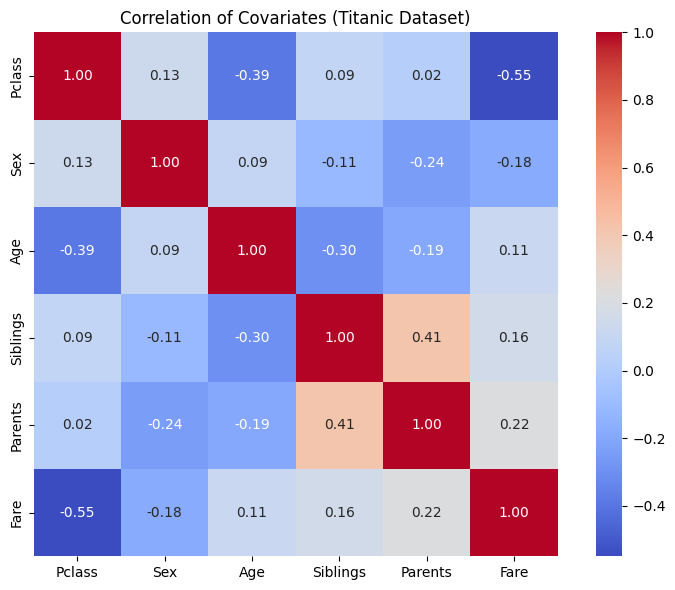

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
corr_matrix = X.corr()

# Plot heatmap of correlations
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation of Covariates (Titanic Dataset)")
plt.tight_layout()
plt.show()

In [6]:
# XGBoost model
model = xgb.XGBClassifier(random_state=666)
model.fit(X_train, y_train)

# Predictions on the test set
predictions = model.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy:.2%}")

from sklearn.metrics import roc_auc_score

# Calculate probabilities for the positive class (1) - test data
probs = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, probs)
print(f"AUC (test data): {auc:.3f}")

# Calculate probabilities for the positive class (1) - training data
probs_train = model.predict_proba(X_train)[:, 1]
auc_train = roc_auc_score(y_train, probs_train)
print(f"AUC (training data): {auc_train:.3f}")

Accuracy: 82.58%
AUC (test data): 0.812
AUC (training data): 0.998


* So, we can expect a correct survival prediction for roughly 83% of the passengers on unseen data (the exact value depends on the `xgboost` version, e.g. 82.6% or 83.7%).
* Note the gap between the AUC on the training data (≈ 1.00) and on the test data (≈ 0.81): the untuned model overfits. Tuning and validation follow in Module 5 (Supervised Learning); for illustrating the absolutely basic classification procedure, this is sufficient here.

**Also interesting**: The trained learner can make a prediction for any combination of features – even for those not found on board:

In [7]:
# Example: Predicting for a hypothetical passenger
new_passenger = pd.DataFrame({
    'Pclass': [1],      # 1st class
    'Sex': [0],         # female (0 = female, 1 = male, as encoded above)
    'Age': [22],        # 22 years old
    'Siblings': [1],    # 1 sibling/spouse aboard
    'Parents': [1],     # 1 parent/child aboard
    'Fare': [7.25]      # ticket price
})
prediction = model.predict(new_passenger)[0]
print(f"Prediction for the hypothetical passenger: {'Survived' if prediction == 1 else 'Not survived'}")

Prediction for the hypothetical passenger: Survived


* In a way, you could say that the classification “hallucinates” the outcome, since the passenger did not exist.
* The model is only trained for (binary) 0/1 statements, but under certain assumptions, (pseudo-)probabilities for outcomes can also be determined.
* The usefulness lies beyond philosophical questions about whether models can/should make attributions:
    * We can use such models to make statements about relationships and constellations that have not been observed or cannot be observed, if they are sufficiently calibrated.
    * **And that is exactly the kind of question that is regularly relevant in actuarial science!**

<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestion: Classification</div>

* Return to this example after you have worked through the content of Module 5 (Supervised Learning).
* Also apply tree-type and/or neural network models here.
* Consider to what extent statements about the suitability for the minority class “survived” can be generalised. Think, for example, of Type I/II errors.

</div>

#### 2.1.2. Regression: Medicare

As another example, we now want to show a regression example. For this, we use the `Medicare` dataset from the USA.

| Feature      | Description   |
| ------------- | ------------- |
| STATE | State code, 1–54 (US states, District of Columbia and territories) |
| YEAR | Survey year, 1–6 (= 1990–1995) |
| TOT_CHG | Total hospital charges [US$] |
| COV_CHG | Hospital charges covered by Medicare [US$] |
| MED_REIB | Medicare reimbursements [US$] |
| TOT_D | Total number of hospital days |
| NUM_DCHG | Number of discharges (hospital cases) |
| AVE_T_D | Average length of stay [days] (TOT_D / NUM_DCHG, rounded) |
| NMSTATE | State abbreviation (e.g. AL = Alabama) |

Depending on the question, various features can be used as the target variable; in this example, `COV_CHG` will be estimated.

In [8]:
# Import libraries

import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

# Load data set
df_med = pd.read_csv("data/Medicare.txt", delimiter="\t")

# View first 10 rows
df_med.head(10)

,STATE,YEAR,TOT_CHG,COV_CHG,MED_REIB,TOT_D,NUM_DCHG,AVE_T_D,NMSTATE
0,1,1,2211617271,2170240349,972752944,1932673,230015,8,AL
1,1,2,2523987347,2468263759,1046016144,1936939,234739,8,AL
2,1,3,2975969979,2922611694,1205791592,2016354,245027,8,AL
3,1,4,3194595003,3149745611,1307982985,1948427,243947,8,AL
4,1,5,3417704863,3384305357,1376211788,1926335,258384,7,AL
5,1,6,3519375275,3492635576,1466220936,1847216,261738,7,AL
6,2,1,64747759,62242279,42083051,51923,6636,8,AK
7,2,2,70600503,67579913,46928596,53051,6940,8,AK
8,2,3,79428741,76550199,56545125,55191,7646,7,AK
9,2,4,86246012,84299106,61186949,53329,7610,7,AK


In [9]:
# target variable
y = df_med['COV_CHG']

# explanatory (independent) variables: all columns except the target COV_CHG, NMSTATE and TOT_CHG
X = df_med.drop(['COV_CHG','NMSTATE','TOT_CHG'],axis=1)

# Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
# Add intercept (statsmodels does not add one automatically)
X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)

# Fit OLS model
model = sm.OLS(y_train, X_train_const)
results = model.fit()

In [11]:
# Model summary
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                COV_CHG   R-squared:                       0.978
Model:                            OLS   Adj. R-squared:                  0.977
Method:                 Least Squares   F-statistic:                     1836.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          8.49e-205
Time:                        14:02:58   Log-Likelihood:                -5538.2
No. Observations:                 259   AIC:                         1.109e+04
Df Residuals:                     252   BIC:                         1.112e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5.847e+08   2.22e+08     -2.634      0.0

In [12]:
# Make predictions
predictions = results.predict(X_test_const)

# Compare predictions with actual values
print("\nFirst 5 predictions vs actual:")
comparison = pd.DataFrame({
    'Actual': y_test.values[:5],
    'Predicted': predictions.values[:5]
})
print(comparison)

# R²-Score calculation
from sklearn.metrics import r2_score
r2 = r2_score(y_test, predictions)
print(f"\nTest R²: {r2:.4f}")


First 5 predictions vs actual:
       Actual     Predicted
0  3870082565  4.302179e+09
1  1993020829  2.109146e+09
2  5851463647  6.929758e+09
3    84299106 -2.578951e+06
4  2538916656  3.101657e+09

Test R²: 0.9730


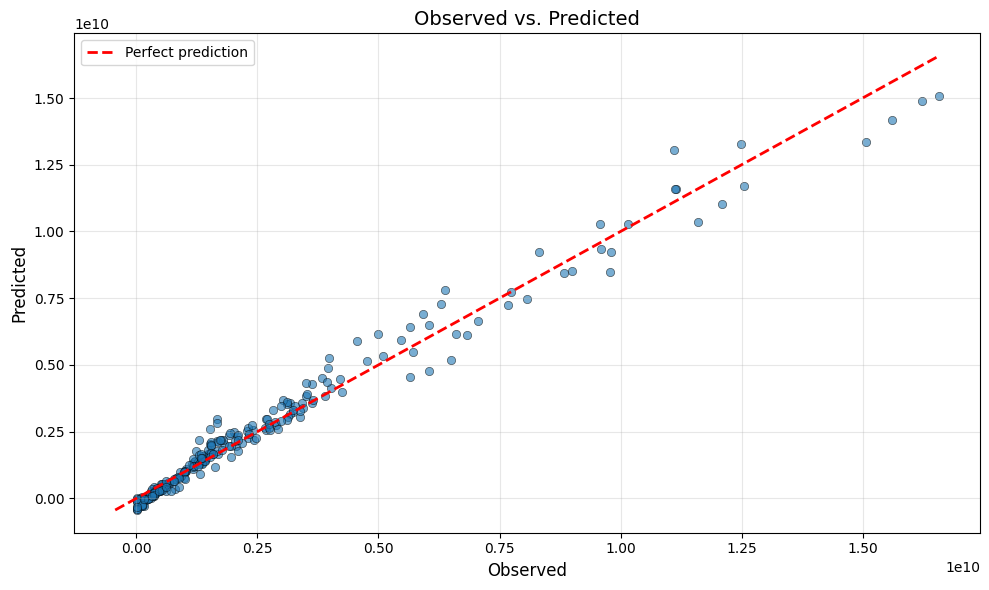

In [13]:
import matplotlib.pyplot as plt

# Collect actual and predicted values
actual = results.model.endog      # Actual y values
predicted = results.fittedvalues  # Predicted y values

# Create plot
plt.figure(figsize=(10, 6))
plt.scatter(actual, predicted, alpha=0.6, edgecolors='k', linewidth=0.5)

# Diagonal reference line
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect prediction')

plt.xlabel('Observed', fontsize=12)
plt.ylabel('Predicted', fontsize=12)
plt.title('Observed vs. Predicted', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Observed vs predicted values (goodness of fit)**
<center><img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/observed_vs_predicted.png" alt="Scatter plot of observed versus fitted COV_CHG values with the diagonal of perfect prediction" style="width:600px; align:auto;" /></center>

**Figure**: Observed values of the target `COV_CHG` plotted against the values fitted by the OLS model (training data, one point per state and year). The red dashed diagonal marks perfect prediction.

* Of course, this is only a very simplified example for regression and the methods that can be used.
* In the following modules, supervised learning will be examined in more detail and further methods, especially tree methods, will be introduced in depth.

_Note_: For a more in-depth analysis of `Medicare.txt` with a fixed-effects model, see [E. W. Frees, R Scripts for Longitudinal and Panel Data – Example 2.2](https://ewfreesres.github.io/Long-Panel-Scripts/fixed-effects-models.html#example-2.2-medicare-hospital-costs-page-26).
<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestion: Regression</div>

* Return to this example after you have worked through the content of Module 5 (Supervised Learning).
* Also apply tree-type and/or neural network models here.

</div>

<img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/copilot_1.png" alt="Screenshot: AI coding assistant (chat panel) in Visual Studio Code (notebook blurred)" style="width:40%; float:right; margin:10px; ">

### 2.2. Coding Assistance

**AI language models can be integrated into IDEs – whether this is useful for your individual workflow must be checked and evaluated:**

* VSCode / PyCharm can integrate assistants via API (OpenAI, Claude, …) or locally (Ollama).
* Code debugging
* Auto-completion
* Write entire functions from prompts
* Useful: “boilerplate”, i.e., code that is simple and “boring”, e.g., EDA

<div style="border-radius:15px; background-color: #aa4444; max-width:98%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #d00; color: #eee;">
<div style="font-weight:bold; font-size:1.5em; background-color: #661105; width:101%; border-radius:15px 15px 0px 0px; margin-left:-15px;color: #eee;">&nbsp;&nbsp;Warning</div>

<b>There are significant dangers in using AI assistance uncritically:</b>

* Data transformations that do not do what you want.
* Data loss or manipulation if agents access the HDD!
* Attractive plots that convey no (or a misleading) message.
* Hallucinated libraries (non-functional or even malicious code!).
* Models that are not actuarially validated (e.g., violate assumptions or overfit).

</div>


## 3. Best Practices and Outlook

### Best Practices

* Overfitting is the big problem with much of today’s data.
* Assumptions must be checked – no AI can do that.
* Primacy of practice: A model can have R² 1.0 and still be useless.
* The newest model is not always the most suitable.

<br><br>

<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Note: Statistician’s Wisdom</div>

 “All models are wrong, but some are useful.”

– George E. P. Box
</div>

### Outlook

* Many other aspects were only touched on very superficially.
* (Good) visualisation is practically a discipline of its own.
* Different approaches require more structured work than _“LOAD-FIT-PREDICT”_.
* (Real) methodological knowledge must be gained through experience, not just through knowledge imparted in the seminar.
* Checking for biases and structural weaknesses (distributions, model assumptions) must come first and can render supposedly “perfect” models (i.e., with good performance) obsolete.

---

## Appendix – Conceptual Knowledge

* A.1 Description of the scope of Python basics
    * Variables and types
    * Control mechanisms
    * Flow concepts
    * Data frames
* A.2 Basics of visualisation

### A.1. The Python Language Scope
#### 1. Basic Data Types and Variables

* Python is a __dynamically typed__ language, which means that the data type of a variable is determined at runtime and does not have to be explicitly declared. Unlike statically typed languages like Java or C++, a variable in Python can change its type during program execution. This flexibility makes prototyping easier but also requires special attention when developing larger systems.

* The basic data types include `int` (integers of arbitrary size), `float` (floating-point numbers according to IEEE 754 standard), `complex` (complex numbers), as well as `str` (character strings) and `bool` (boolean values). Python uses automatic memory management with garbage collection, so developers do not have to worry about manual memory release.

#### 2. File Operations

Working with files is a fundamental part of many programs. Python provides the built-in `open()` function to open files and various modes for reading, writing, and appending. The `with` statement ensures that files are automatically closed, even if errors occur – this is the preferred method for file operations.

The most important modes are `'r'` for reading (default), `'w'` for writing (overwrites existing file), `'a'` for appending, and `'r+'` for reading and writing. For binary files, `'b'` is appended, e.g., `'rb'` or `'wb'`. Up to Python 3.14, the default encoding of text files depends on the operating system (on Windows usually cp1252); only from Python 3.15 on is UTF-8 the default everywhere (PEP 686). Therefore, always specify the encoding explicitly with the `encoding` parameter, as in the examples below: `encoding="utf-8"`.

In [14]:
# Write to file
with open("example.txt", "w", encoding="utf-8") as file:
    file.write("First line\n")
    file.write("Second line\n")
    file.writelines(["Third line\n", "Fourth line\n"])

# Read entire file content
with open("example.txt", "r", encoding="utf-8") as file:
    content = file.read()
    print(content)

# Read line by line (memory efficient)
with open("example.txt", "r", encoding="utf-8") as file:
    for line in file:
        print(line.strip())  # strip removes \n

First line
Second line
Third line
Fourth line

First line
Second line
Third line
Fourth line


In [15]:
# Read all lines as a list
with open("example.txt", "r", encoding="utf-8") as file:
    lines = file.readlines()
    print(lines)

# Append to existing file
with open("example.txt", "a", encoding="utf-8") as file:
    file.write("Additional line\n")

# Check if file exists
import os
if os.path.exists("example.txt"):
    print("File exists")

# Delete file
if os.path.exists("example.txt"):
    os.remove("example.txt")


['First line\n', 'Second line\n', 'Third line\n', 'Fourth line\n']
File exists


For large files, reading line by line should be preferred, as this is memory efficient – the entire file does not have to be kept in memory. The file iterator in Python automatically reads the file in blocks and returns lines. This is especially important for log files or large datasets.

<br>
<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestions</div>

1. Write a program that reads a text file and counts the number of lines, words, and characters (similar to the Unix command `wc`).
2. Create a function that reads a CSV file with comma-separated values and returns it as a list of lists (without external libraries).
3. Implement a function `copy_file(source, target)` that copies a text file.
</div>

#### 3. Operators and Expressions

Python offers a complete set of operators for mathematical calculations, comparisons, and logical operations. Operator precedence follows the rules known from mathematics: exponentiation before multiplication/division before addition/subtraction. Parentheses can be used to explicitly specify the order of evaluation.

An important detail is the difference between division `/` and integer division `//`. The normal division operator always returns a float result (even when dividing two integers), while integer division rounds the result down to the next whole number. The modulo operator `%` returns the remainder of a division and is often used to check if a number is divisible by another.

In [16]:
# Arithmetic Operators
total = 10 + 5
difference = 10 - 5
product = 10 * 5
quotient = 10 / 5  # Result: 2.0 (always float)
floor_division = 10 // 3  # Result: 3
remainder = 10 % 3  # Modulo, Result: 1
exponentiation = 2 ** 8  # Result: 256

# Comparison Operators
print(10 > 5)  # True
print(10 == 10)  # True
print(5 != 3)  # True
print(3 <= 3)  # True

True
True
True
True


In [17]:
# Chained Comparison (Python-specific)
x = 5
print(1 < x < 10)  # True (equivalent to: 1 < x and x < 10)

# Logical Operators
print(True and False)  # False
print(True or False)  # True
print(not True)  # False

# Short-circuit Evaluation
print(False and (1/0))  # False, second expression is not evaluated

True
False
True
False
False


Logical operators in Python use short-circuit evaluation: For `and`, the right operand is only evaluated if the left is `True`; for `or`, only if the left is `False`. This can be used for runtime optimisation and prevents errors if the second expression is only valid under certain conditions.

<br>
<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestions</div>

1. For a given number of minutes, calculate how many hours and how many remaining minutes this corresponds to (use `//` and `%`).
2. Check whether a number is divisible by both 3 and 5.
3. Write an expression that checks whether a value is between 0 and 100 (inclusive), without using parentheses.

</div>

#### 4. Control Structures

Control structures control the program flow and allow for conditional execution and loops. Python is characterised by its use of indentation to structure code, instead of curly braces or keywords like `end`. The convention is four spaces per indentation level, although the interpreter accepts any consistent indentation.

The `if-elif-else` structure allows for branching in the program flow. The condition is checked from top to bottom, and only the first `True` branch is executed. The `else` block is optional and is only executed if none of the previous conditions are met. Python also supports ternary operators in the form `value_if_true if condition else value_if_false`.

In [18]:
# Conditional statements
temperature = 22

if temperature > 25:
    print("It is warm")
elif temperature > 15:
    print("It is mild")
else:
    print("It is cold")

# Ternary operator
status = "even" if temperature % 2 == 0 else "odd"

It is mild


In [19]:
# While loop
counter = 0
while counter < 5:
    print(f"Iteration {counter}")
    counter += 1

# For loop with range
for i in range(5):
    print(f"Run {i}")

# range with start, end, and step size
for i in range(0, 10, 2):  # 0, 2, 4, 6, 8
    print(i)


Iteration 0
Iteration 1
Iteration 2
Iteration 3
Iteration 4
Run 0
Run 1
Run 2
Run 3
Run 4
0
2
4
6
8


In [20]:
# Iterating over sequences
weekdays = ["Monday", "Tuesday", "Wednesday"]
for day in weekdays:
    print(day)

# enumerate for index and value
for index, day in enumerate(weekdays):
    print(f"{index}: {day}")

Monday
Tuesday
Wednesday
0: Monday
1: Tuesday
2: Wednesday


Loops can be exited early with `break` or continued to the next iteration with `continue`. The `range()` function generates a sequence of numbers and is the standard tool for counting loops. It accepts one, two, or three parameters: `range(stop)`, `range(start, stop)`, or `range(start, stop, step)`. It is important to note that the stop argument is exclusive, i.e., `range(5)` generates the numbers 0 to 4.

<br>
<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestions</div>

1. Write a loop that prints the numbers from 1 to 100, but prints “Fizz” for multiples of 3, “Buzz” for multiples of 5, and “FizzBuzz” for multiples of both.
2. Calculate the factorial of a number n (n!) with a while loop.
3. Create a for loop that iterates through a list of temperatures and only prints values above 20°C.

</div>

#### 5. Data Structures

Python offers several built-in data structures, each optimised for different use cases. Choosing the right data structure has a significant impact on code readability and performance.

Lists are ordered, mutable sequences and the most versatile data structure. They can contain elements of different types and support various operations such as adding, removing, and sorting. Access to elements is via a zero-based index. Negative indices count from the end of the list: `-1` refers to the last element, `-2` to the second last, etc. Slicing allows access to subsequences with the notation `list[start:end:step]`.

In [21]:
# Lists (mutable)
numbers = [1, 2, 3, 4, 5]
numbers.append(6)  # Add at the end
numbers.insert(0, 0)  # Insert at position 0
numbers.remove(3)  # Remove first occurrence of 3
numbers[0] = 10  # Change element
last = numbers.pop()  # Remove and return last element

# Slicing
subset = numbers[1:4]  # Index 1 to 3
every_second = numbers[::2]  # Every second element
reversed_list = numbers[::-1]  # Reverse list

In [22]:
# List Comprehensions
squares = [x**2 for x in range(10)]
evens = [x for x in range(20) if x % 2 == 0]
matrix = [[i*j for j in range(5)] for i in range(5)]  # 2D list

# Tuples (immutable)
coordinates = (10.5, 20.3)
point = (1, 2, 3)
# coordinates[0] = 5  # TypeError: tuples are immutable


In [23]:
# Define tuples for unpacking
coordinates = (10.5, 20.3)
point = (1, 2, 3)

# Tuple Unpacking
x, y = coordinates
a, b, c = point

# Dictionaries (key-value pairs)
student = {
    "name": "Anna Müller",
    "student_id": 12345,
    "semester": 3
}
print(student["name"])
student["grade"] = 1.7  # New entry (German grading scale: 1.0 = best, 4.0 = pass)
student.update({"age": 23, "major": "Computer Science"})

Anna Müller


In [24]:
# Dictionary methods
keys = student.keys()
values = student.values()
items = student.items()

# Dictionary comprehension
squares_dict = {x: x**2 for x in range(6)}

# Sets (unique elements, unordered)
set_a = {1, 2, 3, 4}
set_b = {3, 4, 5, 6}
intersection = set_a & set_b        # {3, 4}
union = set_a | set_b               # {1, 2, 3, 4, 5, 6}
difference = set_a - set_b          # {1, 2}
symmetric_difference = set_a ^ set_b  # {1, 2, 5, 6}

Like lists, tuples are ordered sequences, but they are immutable. They are often used for data that belongs together and should not be changed, such as coordinates or database entries. The immutability makes tuples hashable, so they can be used as dictionary keys.

Dictionaries are associative arrays that map keys to values. Since Python 3.7, they are ordered (preserve insertion order). Access to values is in constant time O(1), making dictionaries very efficient. Sets are unordered collections of unique elements and are particularly useful for set operations such as union, intersection, and difference.

<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestions</div>

1. Create a list with the numbers 1 to 10 and use slicing to extract: the first three elements, the last three elements, and every third element.
2. Given two lists: `names = ["Anna", "Ben", "Clara"]` and `grades = [1.7, 2.3, 1.3]`. Create a dictionary that maps names to grades.
3. Write a list comprehension that filters from a list of words only those that have more than 5 letters and start with 'P'.
4. Use sets to find the unique elements that only occur in one of two lists (symmetric difference).

</div>

#### 6. Functions

Functions are fundamental building blocks of programming that allow you to organise code, avoid repetition, and create abstractions. In Python, functions are defined with the `def` keyword, followed by the function name and parameters in parentheses. The function body is indented.

Python distinguishes between positional arguments (order matters) and keyword arguments (passed as name=value). Default values can be defined for parameters, making them optional. When defining a function, parameters without default values must come before those with default values.

In [25]:
# Simple function
def calculate_area(length, width):
    """Calculates the area of a rectangle.
    
    Args:
        length: The length of the rectangle
        width: The width of the rectangle
        
    Returns:
        The calculated area
    """
    return length * width

area = calculate_area(5, 3)

In [26]:
# Default arguments
def power(base, exponent=2):
    return base ** exponent

print(power(4))  # 16
print(power(4, 3))  # 64
print(power(base=2, exponent=10))  # Keyword arguments

# Variable number of arguments
def summate(*numbers):
    """Sums any number of numbers."""
    return sum(numbers)

result = summate(1, 2, 3, 4, 5)

16
64
1024


In [27]:
# Keyword arguments with **kwargs
def create_profile(**data):
    for key, value in data.items():
        print(f"{key}: {value}")

create_profile(name="Anna", age=23, city="Berlin")

# Multiple return values
def statistics(numbers):
    return min(numbers), max(numbers), sum(numbers) / len(numbers)

minimum, maximum, average = statistics([1, 2, 3, 4, 5])

name: Anna
age: 23
city: Berlin


In [28]:
# Lambda functions (anonymous functions)
square = lambda x: x**2
print(square(5))  # 25

summation = lambda x, y: x + y

# Higher-order functions
numbers = [1, 2, 3, 4, 5]
squares = list(map(lambda x: x**2, numbers))
evens = list(filter(lambda x: x % 2 == 0, numbers))

# Sorting with lambda
students = [("Anna", 1.7), ("Ben", 2.3), ("Clara", 1.3)]
sorted_students = sorted(students, key=lambda s: s[1])

25


Docstrings are triple-quoted strings directly after the function definition and serve for documentation. They can be accessed with `help(function_name)`. Functions in Python are first-class objects, i.e., they can be passed as arguments, used as return values, and assigned to variables.

Lambda functions are anonymous functions defined with a single expression. They are useful for short functions passed as arguments to higher-order functions like `map()`, `filter()`, or `sorted()`. For more complex logic, regular functions should be used.

<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestions</div>

1. Write a function `is_prime(n)` that checks if a number is a prime number.
2. Create a function `fibonacci(n)` that returns the first n Fibonacci numbers as a list.
3. Implement a function `statistics(**grades)` that accepts any number of named grades and returns a dictionary with average, minimum, and maximum.
4. Given a list of tuples `[(name, age), ...]`. Sort them first by age (ascending), then by name (alphabetically) using the `sorted()` function and appropriate lambda expressions.

</div>

#### 7. Working with Strings

Strings in Python are immutable sequences of Unicode characters. Python 3 uses UTF-8 encoding by default, which makes working with international characters easier. Strings behave similarly to lists: they can be indexed, sliced, and iterated over, but not directly changed. Any operation that seems to change a string actually creates a new string.

The string class offers numerous methods for common text processing tasks. These methods always return new strings without changing the original. Important methods include transformations (upper, lower, capitalize), checks (startswith, endswith, isdigit), and manipulations (strip, replace, split, join).

In [29]:
# String methods
text = "  Python programming  "
print(text.strip())    # Removes whitespace at the beginning and end
print(text.lstrip())   # Only left side
print(text.rstrip())   # Only right side

print(text.lower())    # All lowercase
print(text.upper())    # All uppercase
print(text.title())    # Capitalises each word
print(text.replace("Python", "Java"))

Python programming
Python programming  
  Python programming
  python programming  
  PYTHON PROGRAMMING  
  Python Programming  
  Java programming  


In [30]:
# String tests
sentence = "Python123"
print(sentence.isalpha())      # False (contains numbers)
print(sentence.isalnum())      # True (alphanumeric)
print("123".isdigit())         # True
print(sentence.startswith("Py"))  # True
print(sentence.endswith("23"))    # True

# String formatting (various methods)
name = "Marie"
age = 23
grade = 1.73

False
True
True
True
True


In [31]:
# f-Strings (preferred, since Python 3.6)
print(f"Name: {name}, Age: {age}")
print(f"Grade: {grade:.1f}")  # One decimal place
print(f"Binary: {age:b}, Hex: {age:x}")  # Number systems

# format method
print("Name: {}, Age: {}".format(name, age))
print("Name: {n}, Age: {a}".format(n=name, a=age))

# Old %-formatting (legacy)
print("Name: %s, Age: %d" % (name, age))


Name: Marie, Age: 23
Grade: 1.7
Binary: 10111, Hex: 17
Name: Marie, Age: 23
Name: Marie, Age: 23
Name: Marie, Age: 23


In [32]:
# String operations
sentence = "Python is an interpreted language"
words = sentence.split()  # Splits at whitespace
parts = sentence.split("e")  # Splits at 'e'
joined = "-".join(words)  # Joins with separator

print(len(sentence))  # Length
print(sentence[0:6])  # Slicing: "Python"
print(sentence.count("e"))  # Frequency of a character
print(sentence.find("inter"))  # Position (or -1)
print(sentence.index("inter"))  # Position (or ValueError)

# Multiline strings and raw strings
poem = """Line 1
Line 2
Line 3"""

windows_path = r"C:\new\folder\test.txt"  # Raw string, no escape sequences
windows_path


33
Python
4
13
13


'C:\\new\\folder\\test.txt'

F-Strings (Formatted String Literals) are the modern and recommended method for string formatting. They allow embedding expressions directly in the string with curly braces. Within the braces, formatting instructions can be specified after a colon: `:.2f` for two decimal places, `:10` for a minimum width of 10 characters, `:<10` for left alignment, etc.

<br>
<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestions</div>

1. Write a function that takes a text and returns the number of words, sentences (separated by '.'), and characters.
2. Create a function `is_palindrome(text)` that checks if a string reads the same forwards and backwards (ignore spaces and case).
3. Given a string with words separated by commas: `"Apple,Pear,Cherry,Banana"`. Extract the words, sort them alphabetically, and output them separated by `" | "`.

</div>

#### 8. Introduction to Pandas

Pandas is the central library for data analysis in Python and was developed by Wes McKinney. It is built on top of NumPy and provides powerful data structures for working with structured data. The two main data structures are Series (one-dimensional) and DataFrame (two-dimensional, comparable to a table).

A Series is essentially an indexed one-dimensional data structure. It consists of an array of values and an array of labels (index). The index can be set explicitly or is automatically created as a consecutive integer. Series support both integer- and label-based indexing and offer vectorised operations that are much faster than Python loops.

In [33]:
# Create Series
temperatures = pd.Series([18, 22, 19, 25, 21], 
                        index=['Mon', 'Tue', 'Wed', 'Thu', 'Fri'])
print(temperatures)


Mon    18
Tue    22
Wed    19
Thu    25
Fri    21
dtype: int64


In [34]:
print(temperatures['Wed'])  # Access by index label
print(temperatures.iloc[2])  # Access by position

19
19


In [35]:
# Series from dictionary
grades = pd.Series({'Anna': 1.7, 'Ben': 2.3, 'Clara': 1.3})

# Series operations (vectorised)
print(temperatures + 5)  # Increase all values by 5
print(temperatures * 1.8 + 32)  # Celsius to Fahrenheit
print(temperatures[temperatures > 20])  # Filtering

Mon    23
Tue    27
Wed    24
Thu    30
Fri    26
dtype: int64
Mon    64.4
Tue    71.6
Wed    66.2
Thu    77.0
Fri    69.8
dtype: float64
Tue    22
Thu    25
Fri    21
dtype: int64


In [36]:
# Create DataFrame (various methods)
data = {
    'Name': ['Anna', 'Ben', 'Clara', 'David'],
    'Age': [23, 25, 22, 24],
    'Grade': [1.7, 2.3, 1.3, 2.0]
}
df = pd.DataFrame(data)
print(df)

    Name  Age  Grade
0   Anna   23    1.7
1    Ben   25    2.3
2  Clara   22    1.3
3  David   24    2.0


In [37]:
# DataFrame from list of dictionaries
students = [
    {'Name': 'Anna', 'Age': 23, 'Grade': 1.7},
    {'Name': 'Ben', 'Age': 25, 'Grade': 2.3}
]
df2 = pd.DataFrame(students)
df2

# DataFrame from CSV
# df = pd.read_csv('file.csv', sep=',', encoding='utf-8')
# df = pd.read_excel('file.xlsx', sheet_name='Sheet1')

,Name,Age,Grade
0,Anna,23,1.7
1,Ben,25,2.3


In [38]:
# Basic DataFrame properties
print(df.shape)      # (4, 3) - rows, columns
print(df.columns)    # column names
print(df.index)      # row index
print(df.dtypes)     # data types of the columns

(4, 3)
Index(['Name', 'Age', 'Grade'], dtype='object')
RangeIndex(start=0, stop=4, step=1)
Name      object
Age        int64
Grade    float64
dtype: object


In [39]:
# Basic functionality
print(df.head())  # first 5 rows
print(df.tail(2))  # last 2 rows
print(df.info())  # overview of DataFrame

    Name  Age  Grade
0   Anna   23    1.7
1    Ben   25    2.3
2  Clara   22    1.3
3  David   24    2.0
    Name  Age  Grade
2  Clara   22    1.3
3  David   24    2.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Name    4 non-null      object 
 1   Age     4 non-null      int64  
 2   Grade   4 non-null      float64
dtypes: float64(1), int64(1), object(1)
memory usage: 228.0+ bytes
None


In [40]:
print(df.describe())  # Statistical summary for numerical columns

             Age   Grade
count   4.000000  4.0000
mean   23.500000  1.8250
std     1.290994  0.4272
min    22.000000  1.3000
25%    22.750000  1.6000
50%    23.500000  1.8500
75%    24.250000  2.0750
max    25.000000  2.3000


* `DataFrames` are two-dimensional, resizable, and potentially heterogeneous tabular data structures.
* Each column is a `Series`, and different columns can have different data types.
* `DataFrames` offer extensive functionality for data manipulation, cleaning, and analysis.
* The `info()` method shows metadata such as data types and the number of non-null values.
* `describe()` calculates statistical metrics for numeric columns.

<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestions</div>

1. Create a Series with the month names as index and random temperatures as values. Calculate the average temperature.
2. Create a DataFrame with at least 5 students, with columns for name, student ID, semester, and grade.
3. Load one of the DataFrames and output the data types of all columns as well as the number of rows and columns.

</div>

#### 9. Data Manipulation with Pandas

* `Pandas` enables efficient filtering, transformation, and aggregation of tabular data.
* The strength of Pandas lies in its ability to express complex data operations in just a few lines of code.
* Pandas works vectorised, meaning operations are performed on entire columns or rows at once, without the need for explicit loops.

* For accessing data, Pandas offers various methods:
    * Direct column access with square brackets, `loc[]` for label-based indexing,
    * `iloc[]` for position-based indexing.

* This distinction is important as it covers different use cases:
    * `loc[]` works with index and column names.
    * `iloc[]` works with numeric positions.

In [41]:
# Sample data
students = pd.DataFrame({
    'Name': ['Anna', 'Ben', 'Clara', 'David', 'Emma'],
    'Age': [23, 25, 22, 24, 23],
    'Department': ['Computer Science', 'Mathematics', 'Computer Science', 'Physics', 'Mathematics'],
    'Grade': [1.7, 2.3, 1.3, 2.0, 1.8]
})
students

,Name,Age,Department,Grade
0,Anna,23,Computer Science,1.7
1,Ben,25,Mathematics,2.3
2,Clara,22,Computer Science,1.3
3,David,24,Physics,2.0
4,Emma,23,Mathematics,1.8


In [42]:
# Column selection
names = students['Name']  # Series
selection = students[['Name', 'Grade']]  # DataFrame (double brackets!)

# Access with loc (label-based) and iloc (position-based)
first_row = students.loc[0]  # First row by index
first_row_pos = students.iloc[0]  # First row by position
cell = students.loc[0, 'Name']  # Specific cell
range_rows = students.loc[0:2, ['Name', 'Grade']]  # Multiple rows and columns

In [43]:
# Filter rows (Boolean Indexing)
cs_students = students[students['Department'] == 'Computer Science']
good_grades = students[students['Grade'] < 2.0]
combined = students[(students['Grade'] < 2.0) & (students['Age'] > 22)]

# Query method (alternative syntax)
cs_students_alt = students.query('Department == "Computer Science"')
complex_query = students.query('Grade < 2.0 and Age > 22')

In [44]:
# Add new columns
students['Passed'] = students['Grade'] <= 4.0  # German grading scale: 1.0 = best, 4.0 = pass
students['GradePoints'] = 100 - (students['Grade'] - 1) * 20
students['AgeGroup'] = students['Age'].apply(
    lambda x: 'young' if x < 24 else 'older'
)

# Edit columns with vectorised methods
students['Name_upper'] = students['Name'].str.upper()
students['Grade_rounded'] = students['Grade'].round(1)


In [45]:
# Sorting
sorted_by_grade = students.sort_values('Grade')
sorted_multiple = students.sort_values(['Department', 'Grade'])
sorted_descending = students.sort_values('Grade', ascending=False)

# Grouping and aggregation
by_department = students.groupby('Department')['Grade'].mean()
print(by_department)


Department
Computer Science    1.50
Mathematics         2.05
Physics             2.00
Name: Grade, dtype: float64


In [46]:
#  Aggregations
aggregated = students.groupby('Department').agg({
    'Grade': ['mean', 'min', 'max', 'count'],
    'Age': 'mean'
})
aggregated

Grade                   Age
                  mean  min  max count  mean
Department                                  
Computer Science  1.50  1.3  1.7     2  22.5
Mathematics       2.05  1.8  2.3     2  24.0
Physics           2.00  2.0  2.0     1  24.0

In [47]:

# Custom aggregation
def grade_range(x):
    return x.max() - x.min()

range_by_department = students.groupby('Department')['Grade'].agg(grade_range)
range_by_department

Department
Computer Science    0.4
Mathematics         0.5
Physics             0.0
Name: Grade, dtype: float64

In [48]:
# Pivot-Table
pivot = students.pivot_table(
    values='Grade',
    index='Department',
    aggfunc=['mean', 'count']
)
pivot

,mean,count
,Grade,Grade
Department,,
Computer Science,1.50,2
Mathematics,2.05,2
Physics,2.00,1


* The `groupby()` method is one of the most powerful tools in Pandas and follows the split-apply-combine paradigm: The data is grouped by one or more criteria, a function is applied to each group, and the results are combined into a new data structure. This is especially useful for statistical analyses and reports.

* The `apply()` method allows the application of arbitrary functions to DataFrame columns or rows. For simple operations, it is flexible, but can be slower than vectorised Pandas operations. Where possible, built-in Pandas methods should be preferred.

<div style="border-radius:15px; background-color:#A0D5F1; width:95%; padding-left:15px; padding-right:15px; box-sizing:border-box;border:1px solid #029;">
<div style="font-weight:bold; font-size:1.5em; background-color:#0F2B72; width:90%;border-radius:15px 15px 0px 0px;margin-left:-15px;color:#fff;">&nbsp;&nbsp;Exercise Suggestions</div>

1. Given a DataFrame with product sales (product, category, price, quantity). Calculate the total sales per category.
2. Filter from a student DataFrame all persons who are either in the 3rd semester or have a grade better than 2.0.
3. Create a new column that divides age into age groups: “18-22”, “23-27”, “28+” (use `pd.cut()` or your own function with `apply()`).
4. Use `groupby()` and `agg()` to calculate the average grade and the number of students for each department.

</div>

### A.2. Basics of Plotting and Visualisation
* The library `matplotlib.pyplot` is the __standard interface__ for creating figures of data, shapes, and graphic objects.
* It is useful to become familiar with the __general syntax__ and the individual components of plots.
* Most higher-level __graphics libraries__ are based on `matplotlib` under the hood.
* `seaborn` and the plotting functions of `pandas`, for example, build on `matplotlib`; `plotly`, by contrast, is an independent library for interactive, browser-based charts.

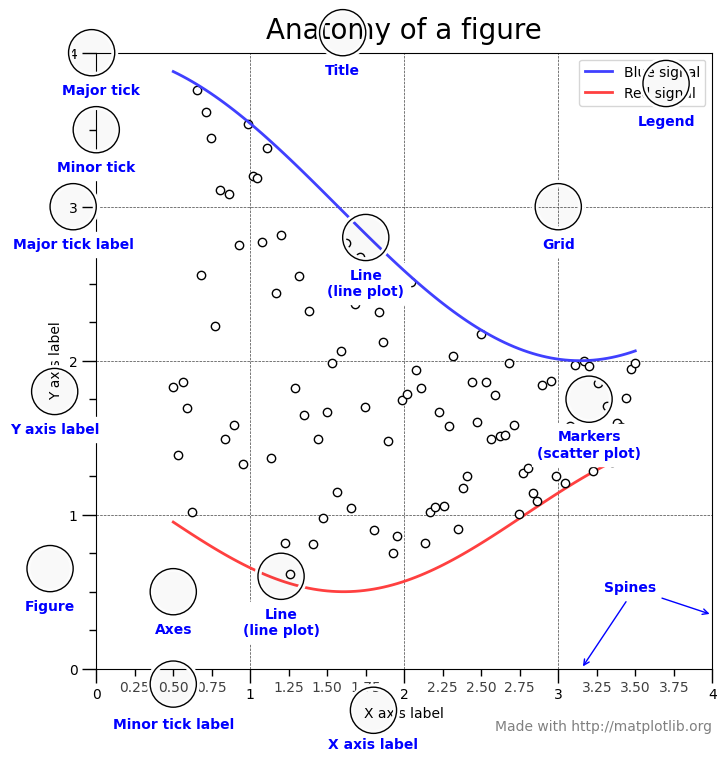

In [49]:
# Adapted from https://matplotlib.org/stable/gallery/showcase/anatomy.html
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FuncFormatter
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(666)

X = np.linspace(0.5, 3.5, 100)
Y1 = 3+np.cos(X)
Y2 = 1+np.cos(1+X/0.75)/2
Y3 = np.random.uniform(Y1, Y2, len(X))

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(1, 1, 1, aspect=1)


def minor_tick(x, pos):
    if not x % 1.0:
        return ""
    return "%.2f" % x

ax.xaxis.set_major_locator(MultipleLocator(1.000))
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_major_locator(MultipleLocator(1.000))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.xaxis.set_minor_formatter(FuncFormatter(minor_tick))

ax.set_xlim(0, 4)
ax.set_ylim(0, 4)

ax.tick_params(which='major', width=1.0)
ax.tick_params(which='major', length=10)
ax.tick_params(which='minor', width=1.0, labelsize=10)
ax.tick_params(which='minor', length=5, labelsize=10, labelcolor='0.25')

ax.grid(linestyle="--", linewidth=0.5, color='.25', zorder=-10)

ax.plot(X, Y1, c=(0.25, 0.25, 1.00), lw=2, label="Blue signal", zorder=10)
ax.plot(X, Y2, c=(1.00, 0.25, 0.25), lw=2, label="Red signal")
ax.plot(X, Y3, linewidth=0,
        marker='o', markerfacecolor='w', markeredgecolor='k')

ax.set_title("Anatomy of a figure", fontsize=20, verticalalignment='bottom')
ax.set_xlabel("X axis label")
ax.set_ylabel("Y axis label")

ax.legend(loc="upper right")


def circle(x, y, radius=0.15):
    from matplotlib.patches import Circle
    from matplotlib.patheffects import withStroke
    circle = Circle((x, y), radius, clip_on=False, zorder=10, linewidth=1,
                    edgecolor='black', facecolor=(0, 0, 0, .0125),
                    path_effects=[withStroke(linewidth=5, foreground='w')])
    ax.add_artist(circle)


def text(x, y, text):
    ax.text(x, y, text, backgroundcolor="white",
            ha='center', va='top', weight='bold', color='blue')


# Minor tick
circle(0.50, -0.10)
text(0.50, -0.32, "Minor tick label")

# Major tick
circle(-0.03, 4.00)
text(0.03, 3.80, "Major tick")

# Minor tick
circle(0.00, 3.50)
text(0.00, 3.30, "Minor tick")

# Major tick label
circle(-0.15, 3.00)
text(-0.15, 2.80, "Major tick label")

# X Label
circle(1.80, -0.27)
text(1.80, -0.45, "X axis label")

# Y Label
circle(-0.27, 1.80)
text(-0.27, 1.6, "Y axis label")

# Title
circle(1.60, 4.13)
text(1.60, 3.93, "Title")

# Blue plot
circle(1.75, 2.80)
text(1.75, 2.60, "Line\n(line plot)")

# Red plot
circle(1.20, 0.60)
text(1.20, 0.40, "Line\n(line plot)")

# Scatter plot
circle(3.20, 1.75)
text(3.20, 1.55, "Markers\n(scatter plot)")

# Grid
circle(3.00, 3.00)
text(3.00, 2.80, "Grid")

# Legend
circle(3.70, 3.80)
text(3.70, 3.60, "Legend")

# Axes
circle(0.5, 0.5)
text(0.5, 0.3, "Axes")

# Figure
circle(-0.3, 0.65)
text(-0.3, 0.45, "Figure")

color = 'blue'
ax.annotate('Spines', xy=(4.0, 0.35), xytext=(3.3, 0.5),
            weight='bold', color=color,
            arrowprops=dict(arrowstyle='->',
                            connectionstyle="arc3",
                            color=color))

ax.annotate('', xy=(3.15, 0.0), xytext=(3.45, 0.45),
            weight='bold', color=color,
            arrowprops=dict(arrowstyle='->',
                            connectionstyle="arc3",
                            color=color))

ax.text(4.0, -0.4, "Made with http://matplotlib.org",
        fontsize=10, ha="right", color='.5')

plt.show();


**Elements of `matplotlib` Figures**
<center><img src="https://raw.githubusercontent.com/simonhatzesberger/fit4ai-compact-20261119/main/images/matplotlib_elements.png" alt="Anatomy of a matplotlib figure with its labelled elements" style="width:475px; align:auto;" /></center>

**Figure**: Framework elements of `matplotlib`. The code to create this graphic is included in the notebook (previous cell) but omitted from the slides.

#### Plotting Example: Line Plot

```python
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 10, 100)
y = np.sin(x)

plt.plot(x, y)
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.title('Simple Line Plot')
plt.show()
```

* The code above creates a simple line plot of the sine function.

#### Interactive Visualisation with Plotly

* `plotly` enables interactive, web-based visualisations directly in the notebook.
* The syntax is similar to matplotlib, but the output is interactive (zoom, hover, etc.).

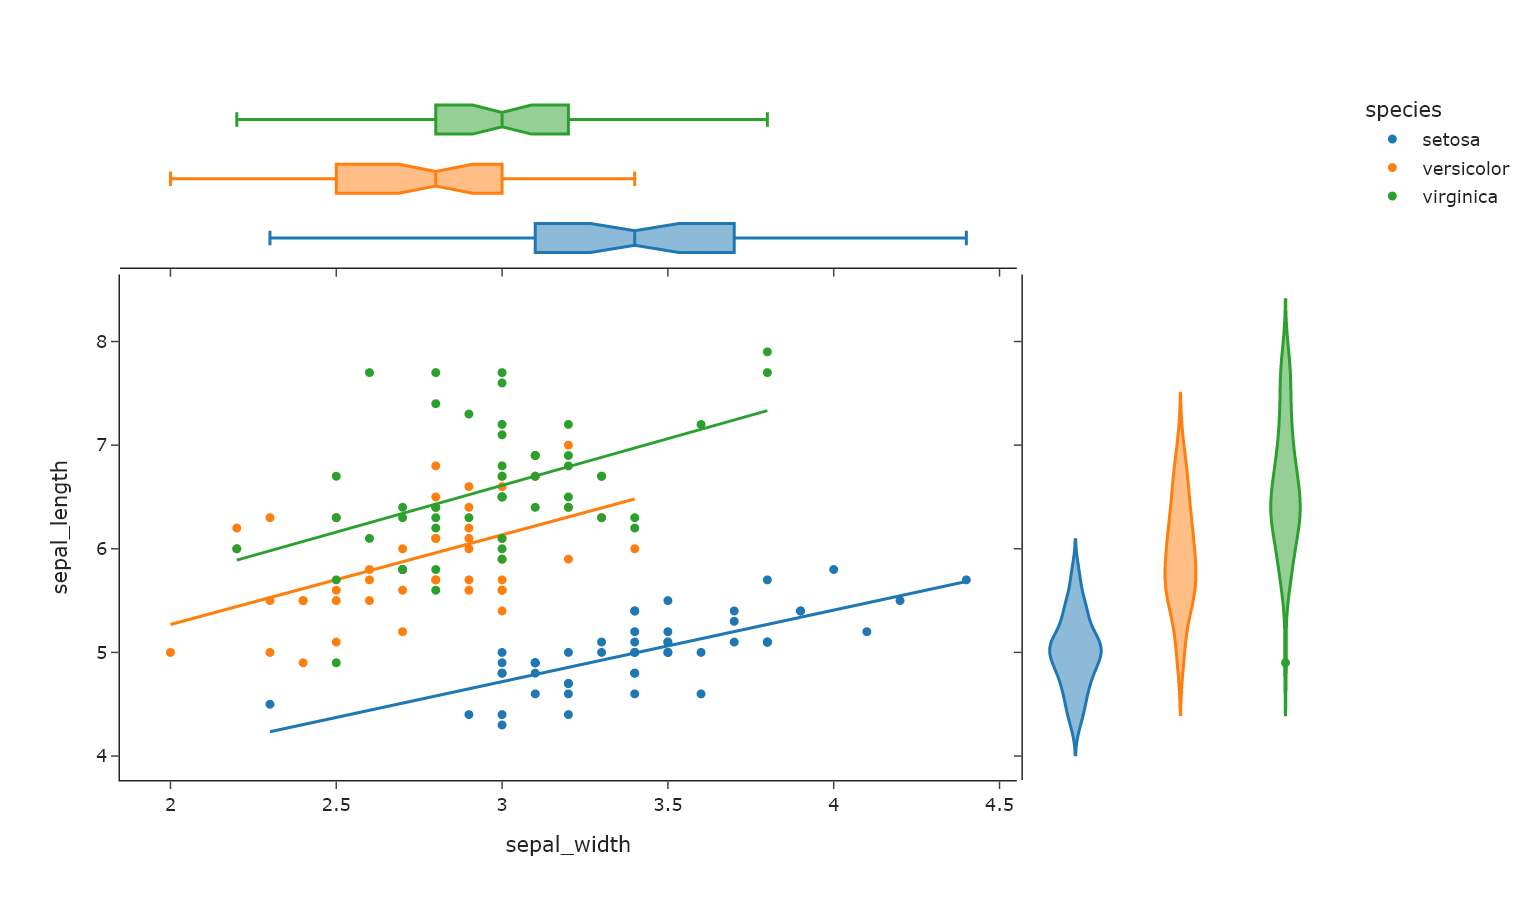

In [50]:
import plotly.express as px
df = px.data.iris()
fig = px.scatter(df, x="sepal_width", y="sepal_length",
color="species", marginal_y="violin",marginal_x="box",
trendline="ols", template="simple_white",
width=1024, height=600);
fig.show()

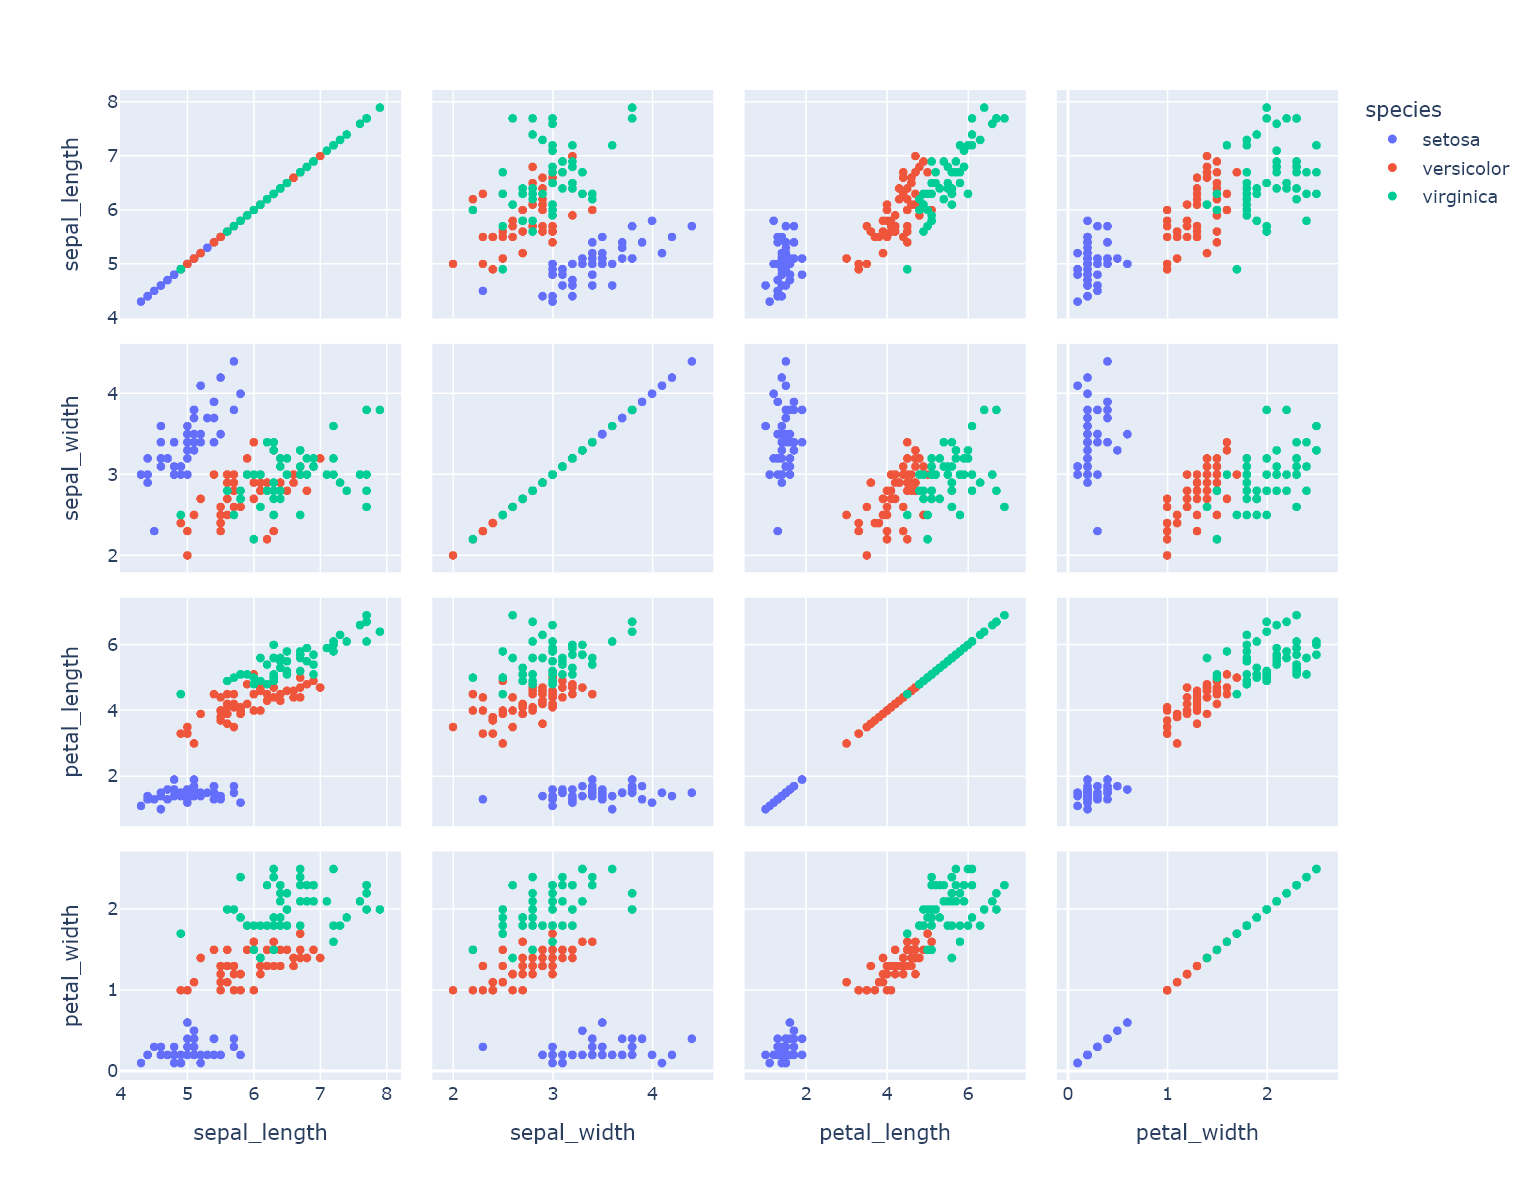

In [51]:
import plotly.express as px
# Scatter matrix: every feature plotted against every other feature
# (px.scatter_matrix replaces ff.create_scatterplotmatrix, which newer plotly versions no longer provide)
fig = px.scatter_matrix(df, dimensions=['sepal_length', 'sepal_width', 'petal_length', 'petal_width'],
                        color='species', width=1024, height=800)
fig.show()

#### Summary: Visualisation Libraries

* `matplotlib` is the standard for static plots in Python.
* `plotly` and other libraries (e.g., seaborn, bokeh, altair) offer interactive and/or more visually appealing graphics.
* The choice of library depends on the use case: publication, exploration, or presentation.

### Thank you for your attention!

If you have any questions or suggestions, feel free to reach out.

We wish you much success and enjoyment in your further exploration of Data Science and AI!